# Gemma-2B — Repeatability of instruction-following evaluation

**Study design.** Fifteen complete evaluations of the same 541 prompts were performed on one local serving system. Five concurrent-request settings (8, 32, 64, 128, 256) were tested, with three repetitions per setting.

**Objective.** Quantify variation in instruction-following accuracy, end-to-end evaluation throughput, and individual generated responses under otherwise fixed evaluation conditions.

## 1. Experimental configuration

| Component | Configuration |
|---|---|
| Model | `google/gemma-2b`, revision `9cf48e52b224239de00d483ec8eb84fb8d0f3a3a` |
| Evaluation framework | EleutherAI Language Model Evaluation Harness, pinned source revision `d6de81643928d653435c431bae19945d41d32520` |
| Dataset | `google/IFEval`, revision `966cd89545d6b6acfd7638bc708b98261ca58e84` |
| Evaluation task | `ifeval_pinned`, zero demonstrated examples; strict and loose instruction checking |
| Generation | Sampling disabled, temperature zero, maximum 1,280 generated tokens |
| Serving | vLLM `0.33.0` (experimental configuration); maximum model length 4,096 tokens |

The evaluator uses the original response records and aggregate result files. Execution time is read from each run's `time.txt`. Execute the notebook with `llm_benchmarks/capability/notebooks` as the working directory, or adjust the relative data path below.

In [1]:
# Import the libraries required for raw-data analysis and visualization.
import hashlib
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display


# Define the expected experiment structure and pinned revisions.
DATA_DIRECTORY = Path("../results/ifeval-repro")
CONCURRENT_REQUESTS = (8, 32, 64, 128, 256)
REPETITIONS = (1, 2, 3)
PROMPTS_PER_RUN = 541

MODEL_REVISION = "9cf48e52b224239de00d483ec8eb84fb8d0f3a3a"
DATASET_REVISION = "966cd89545d6b6acfd7638bc708b98261ca58e84"

if not DATA_DIRECTORY.is_dir():
  raise FileNotFoundError(f"Evaluation directory not found: {DATA_DIRECTORY.resolve()}")

## 2. Accuracy and evaluation throughput

**Prompt-level accuracy** measures the proportion of prompts for which every instruction is satisfied. **Instruction-level accuracy** measures the proportion of all individual instructions satisfied; prompts can contain different numbers of instructions. Strict and loose variants apply different checking rules.

Results are summarized as the mean and **sample standard deviation across three independent executions**. End-to-end throughput counts evaluated prompts per second, including evaluation overhead. These quantities are distinct from the standard errors provided by the evaluation framework.

In [2]:
# Read aggregate metrics and measured execution time from all fifteen runs.
run_records = []

for concurrency in CONCURRENT_REQUESTS:
  for repetition in REPETITIONS:
    run_directory = DATA_DIRECTORY / f"c{concurrency}" / f"run-{repetition}"
    result_files = list((run_directory / "google__gemma-2b").glob("results_*.json"))

    if len(result_files) != 1:
      raise ValueError(f"Expected one aggregate result in {run_directory}")

    with result_files[0].open(encoding="utf-8") as result_file:
      result = json.load(result_file)

    model_config = result["config"]["model_args"]
    task_config = result["configs"]["ifeval_pinned"]
    metrics = result["results"]["ifeval_pinned"]
    duration_seconds = float((run_directory / "time.txt").read_text().strip())

    # Reject incomplete runs or changes in the fixed experimental settings.
    assert model_config["model"] == "google/gemma-2b"
    assert model_config["revision"] == MODEL_REVISION
    assert model_config["num_concurrent"] == concurrency
    assert task_config["dataset_kwargs"]["revision"] == DATASET_REVISION
    assert task_config["generation_kwargs"]["temperature"] == 0.0
    assert task_config["generation_kwargs"]["do_sample"] is False
    assert task_config["generation_kwargs"]["max_gen_toks"] == 1280
    assert result["n-shot"]["ifeval_pinned"] == 0
    assert result["config"]["limit"] is None
    assert metrics["sample_len"] == PROMPTS_PER_RUN
    assert duration_seconds > 0

    run_records.append({
      "run": f"c{concurrency}-r{repetition}",
      "concurrency": concurrency,
      "repetition": repetition,
      "strict_prompt_percent": 100 * metrics["prompt_level_strict_acc,none"],
      "loose_prompt_percent": 100 * metrics["prompt_level_loose_acc,none"],
      "strict_instruction_percent": 100 * metrics["inst_level_strict_acc,none"],
      "loose_instruction_percent": 100 * metrics["inst_level_loose_acc,none"],
      "runtime_minutes": duration_seconds / 60,
      "prompts_per_second": PROMPTS_PER_RUN / duration_seconds,
      "framework_version": result["lm_eval_version"],
      "directory": run_directory,
    })

runs = pd.DataFrame(run_records)

# Confirm that the evaluation framework version was constant.
if runs["framework_version"].nunique() != 1:
  raise ValueError("The evaluation framework version changed between runs")

print(f"Loaded {len(runs)} complete evaluation runs")

Loaded 15 complete evaluation runs


In [3]:
# Read individual responses and retain only fields required for comparison.
response_records = []

for run in runs.itertuples(index=False):
  sample_files = list((run.directory / "google__gemma-2b").glob("samples_ifeval_pinned_*.jsonl"))

  if len(sample_files) != 1:
    raise ValueError(f"Expected one response file in {run.directory}")

  with sample_files[0].open(encoding="utf-8") as sample_file:
    for line in sample_file:
      sample = json.loads(line)
      strict_flags = tuple(sample["inst_level_strict_acc"])
      loose_flags = tuple(sample["inst_level_loose_acc"])
      generated_text = sample["filtered_resps"][0]

      # Each prompt may contain more than one independently checked instruction.
      if len(strict_flags) != len(sample["doc"]["instruction_id_list"]):
        raise ValueError(f"Unexpected instruction count in {run.run}")

      if len(loose_flags) != len(strict_flags):
        raise ValueError(f"Inconsistent instruction counts in {run.run}")

      response_records.append({
        "run": run.run,
        "concurrency": run.concurrency,
        "repetition": run.repetition,
        "question": sample["doc_id"],
        "document_hash": sample["doc_hash"],
        "prompt_hash": sample["prompt_hash"],
        "target_hash": sample["target_hash"],
        "strict_prompt": bool(sample["prompt_level_strict_acc"]),
        "loose_prompt": bool(sample["prompt_level_loose_acc"]),
        "strict_instructions": strict_flags,
        "loose_instructions": loose_flags,
        "generated_text_hash": hashlib.sha256(generated_text.encode("utf-8")).hexdigest(),
      })

responses = pd.DataFrame(response_records)

# Every run must contain the same prompts, with exactly one record per prompt.
if not responses.groupby("run").size().eq(PROMPTS_PER_RUN).all():
  raise ValueError("Incomplete response files")

if responses.duplicated(["run", "question"]).any():
  raise ValueError("Repeated prompt within a run")

if not responses.groupby("question")["run"].nunique().eq(len(runs)).all():
  raise ValueError("Different prompt sets across runs")

input_variants = responses.groupby("question")[["document_hash", "prompt_hash", "target_hash"]].nunique()

if input_variants.gt(1).any().any():
  raise ValueError("Evaluation inputs changed between runs")

# Recalculate every metric from the original prompt and instruction outcomes.
for run in runs.itertuples(index=False):
  group = responses.loc[responses["run"] == run.run]

  calculated = {
    "strict_prompt_percent": 100 * group["strict_prompt"].mean(),
    "loose_prompt_percent": 100 * group["loose_prompt"].mean(),
    "strict_instruction_percent": 100 * sum(map(sum, group["strict_instructions"])) / sum(map(len, group["strict_instructions"])),
    "loose_instruction_percent": 100 * sum(map(sum, group["loose_instructions"])) / sum(map(len, group["loose_instructions"])),
  }

  for metric_name, value in calculated.items():
    if abs(value - getattr(run, metric_name)) > 1e-8:
      raise ValueError(f"Aggregate metric mismatch: {run.run}, {metric_name}")

print(f"Validated {len(responses):,} responses to {responses['question'].nunique():,} identical prompts")

Validated 8,115 responses to 541 identical prompts


In [4]:
# Summarize all four accuracy metrics and end-to-end throughput across runs.
summary = (
  runs.groupby("concurrency")
  .agg(
    strict_prompt_mean=("strict_prompt_percent", "mean"),
    strict_prompt_standard_deviation=("strict_prompt_percent", "std"),
    loose_prompt_mean=("loose_prompt_percent", "mean"),
    loose_prompt_standard_deviation=("loose_prompt_percent", "std"),
    strict_instruction_mean=("strict_instruction_percent", "mean"),
    strict_instruction_standard_deviation=("strict_instruction_percent", "std"),
    loose_instruction_mean=("loose_instruction_percent", "mean"),
    loose_instruction_standard_deviation=("loose_instruction_percent", "std"),
    mean_runtime_minutes=("runtime_minutes", "mean"),
    runtime_standard_deviation=("runtime_minutes", "std"),
    mean_prompts_per_second=("prompts_per_second", "mean"),
    throughput_standard_deviation=("prompts_per_second", "std"),
  )
  .reset_index()
)

# Present means and standard deviations together in a compact report table.
report = summary[["concurrency"]].copy()

for metric, label in [
  ("strict_prompt", "Strict prompts (%)"),
  ("loose_prompt", "Loose prompts (%)"),
  ("strict_instruction", "Strict instructions (%)"),
  ("loose_instruction", "Loose instructions (%)"),
]:
  report[label] = summary[f"{metric}_mean"].map("{:.2f}".format) + " ± " + summary[f"{metric}_standard_deviation"].map("{:.2f}".format)

for mean, deviation, label in [
  ("mean_runtime_minutes", "runtime_standard_deviation", "Runtime (minutes)"),
  ("mean_prompts_per_second", "throughput_standard_deviation", "Throughput (prompts/second)"),
]:
  report[label] = summary[mean].map("{:.2f}".format) + " ± " + summary[deviation].map("{:.2f}".format)

display(report)

,concurrency,Strict prompts (%),Loose prompts (%),Strict instructions (%),Loose instructions (%),Runtime (minutes),Throughput (prompts/second)
0,8,14.42 ± 0.49,17.13 ± 0.21,24.82 ± 0.24,27.86 ± 0.37,9.87 ± 0.12,0.91 ± 0.01
1,32,13.86 ± 0.67,16.57 ± 0.70,24.50 ± 0.50,27.50 ± 0.30,3.09 ± 0.06,2.92 ± 0.06
2,64,14.23 ± 0.18,17.25 ± 0.28,24.58 ± 0.42,27.98 ± 0.50,1.89 ± 0.05,4.78 ± 0.13
3,128,13.99 ± 0.56,16.82 ± 0.64,24.62 ± 0.66,27.74 ± 0.82,1.41 ± 0.03,6.42 ± 0.12
4,256,14.36 ± 0.38,16.88 ± 0.28,24.86 ± 0.42,27.74 ± 0.48,1.38 ± 0.03,6.55 ± 0.16


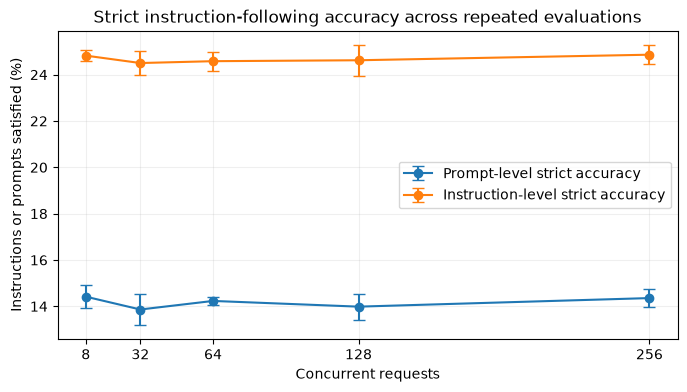

In [5]:
# Visualize strict accuracy and variation between three independent runs.
figure, axis = plt.subplots(figsize=(8, 4))

for metric, deviation, label in [
  ("strict_prompt_mean", "strict_prompt_standard_deviation", "Prompt-level strict accuracy"),
  ("strict_instruction_mean", "strict_instruction_standard_deviation", "Instruction-level strict accuracy"),
]:
  axis.errorbar(
    summary["concurrency"],
    summary[metric],
    yerr=summary[deviation],
    fmt="o-",
    capsize=4,
    label=label,
  )

axis.set(
  xlabel="Concurrent requests",
  ylabel="Instructions or prompts satisfied (%)",
  title="Strict instruction-following accuracy across repeated evaluations",
)
axis.set_xticks(CONCURRENT_REQUESTS)
axis.grid(alpha=0.2)
axis.legend()
plt.show()

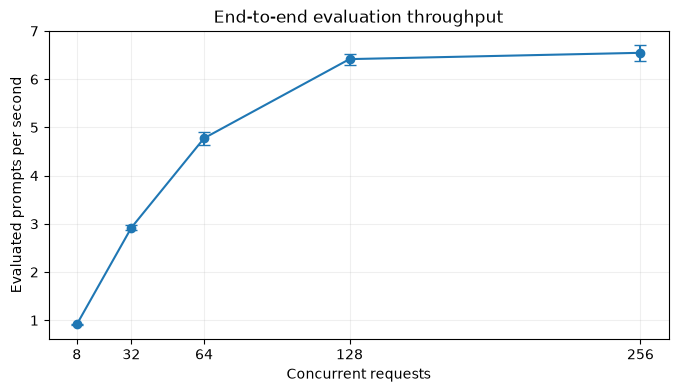

In [6]:
# Compare end-to-end throughput, including evaluation-framework overhead.
figure, axis = plt.subplots(figsize=(8, 4))

axis.errorbar(
  summary["concurrency"],
  summary["mean_prompts_per_second"],
  yerr=summary["throughput_standard_deviation"],
  fmt="o-",
  capsize=4,
)

axis.set(
  xlabel="Concurrent requests",
  ylabel="Evaluated prompts per second",
  title="End-to-end evaluation throughput",
)
axis.set_xticks(CONCURRENT_REQUESTS)
axis.grid(alpha=0.2)
plt.show()

## 3. Repeatability of individual responses

For each prompt, the three repetitions at the same concurrency setting are compared. A disagreement is counted if **at least two repetitions differ**. This comparison distinguishes strict prompt-level compliance, strict outcomes for individual instructions, and the complete generated text.

These percentages describe disagreements across three repetitions; they are not pairwise disagreement probabilities. Changes in text do not necessarily change the evaluation outcome.

In [7]:
# Reshape the response records so each row is one prompt and each column a run.
comparison_records = []

for concurrency, group in responses.groupby("concurrency"):
  strict_prompts = group.pivot(index="question", columns="repetition", values="strict_prompt")
  strict_instructions = group.pivot(index="question", columns="repetition", values="strict_instructions")
  generated_texts = group.pivot(index="question", columns="repetition", values="generated_text_hash")

  # A prompt counts as changed when more than one distinct value occurs
  # across its three repetitions. The mean of these flags is a proportion.
  comparison_records.append({
    "concurrency": concurrency,
    "strict_prompt_disagreement_percent": 100 * strict_prompts.nunique(axis=1).gt(1).mean(),
    "instruction_outcome_disagreement_percent": 100 * strict_instructions.nunique(axis=1).gt(1).mean(),
    "generated_text_disagreement_percent": 100 * generated_texts.nunique(axis=1).gt(1).mean(),
  })

comparison = pd.DataFrame(comparison_records)
display(comparison.round(3))

,concurrency,strict_prompt_disagreement_percent,instruction_outcome_disagreement_percent,generated_text_disagreement_percent
0,8,2.403,5.360,53.050
1,32,3.512,6.470,62.847
2,64,4.436,8.133,66.728
3,128,4.436,8.872,68.762
4,256,5.360,9.797,68.577


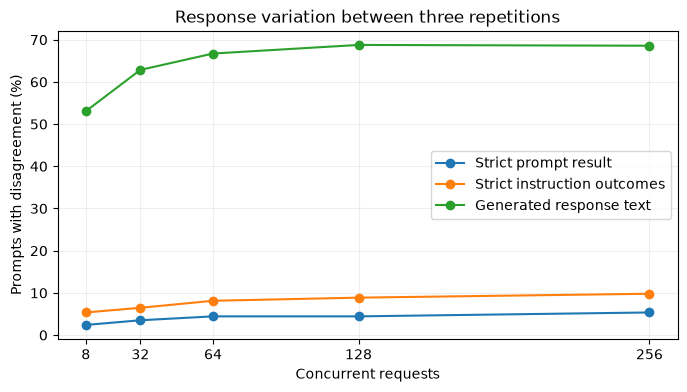

In [8]:
# Visualize how often the same prompt produces different results or text.
figure, axis = plt.subplots(figsize=(8, 4))

for metric, label in [
  ("strict_prompt_disagreement_percent", "Strict prompt result"),
  ("instruction_outcome_disagreement_percent", "Strict instruction outcomes"),
  ("generated_text_disagreement_percent", "Generated response text"),
]:
  axis.plot(comparison["concurrency"], comparison[metric], "o-", label=label)

axis.set(
  xlabel="Concurrent requests",
  ylabel="Prompts with disagreement (%)",
  title="Response variation between three repetitions",
)
axis.set_xticks(CONCURRENT_REQUESTS)
axis.grid(alpha=0.2)
axis.legend()
plt.show()

## 4. Confidence intervals from prompt resampling

For each concurrency setting, **5,000 bootstrap samples** are drawn from the 541 prompts, with replacement and a fixed random seed. Every sampled prompt retains **all three observed repetitions and all instructions within that prompt**. Prompt accuracy is averaged across the sampled prompts; instruction accuracy is calculated from the total number of fulfilled instructions divided by the total number of instructions. Percentile-based **95% confidence intervals** are reported for accuracy and three-run disagreement.

These intervals describe **prompt-selection uncertainty conditional on the observed runs**, not the uncertainty of future benchmark executions. Run-to-run variation is reported separately as the sample standard deviation (Section 2). The fixed benchmark prompts are not a random sample from all possible user requests.


In [9]:
# Resample whole prompts, retaining the three answers and all their instructions.
# This preserves the fact that multiple instructions belong to the same prompt.
BOOTSTRAP_SAMPLES = 5000
BOOTSTRAP_SEED = 12345

random_generator = np.random.default_rng(BOOTSTRAP_SEED)
interval_records = []

for concurrency, group in responses.groupby("concurrency"):
  # Place the three repetitions of each prompt in adjacent columns.
  strict_prompts = group.pivot(index="question", columns="repetition", values="strict_prompt")
  loose_prompts = group.pivot(index="question", columns="repetition", values="loose_prompt")
  strict_instructions = group.pivot(index="question", columns="repetition", values="strict_instructions")
  loose_instructions = group.pivot(index="question", columns="repetition", values="loose_instructions")
  generated_texts = group.pivot(index="question", columns="repetition", values="generated_text_hash")

  # Sum fulfilled instructions across repetitions, but retain each prompt's
  # total number of instructions as the denominator for instruction accuracy.
  strict_instruction_counts = strict_instructions.apply(lambda column: column.map(sum)).sum(axis=1)
  loose_instruction_counts = loose_instructions.apply(lambda column: column.map(sum)).sum(axis=1)
  instruction_totals = strict_instructions.iloc[:, 0].map(len) * len(REPETITIONS)

  prompt_values = np.column_stack([
    strict_prompts.to_numpy(dtype=float).mean(axis=1),
    loose_prompts.to_numpy(dtype=float).mean(axis=1),
    strict_instruction_counts.to_numpy(dtype=float),
    loose_instruction_counts.to_numpy(dtype=float),
    instruction_totals.to_numpy(dtype=float),
    strict_prompts.nunique(axis=1).gt(1).to_numpy(dtype=float),
    strict_instructions.nunique(axis=1).gt(1).to_numpy(dtype=float),
    generated_texts.nunique(axis=1).gt(1).to_numpy(dtype=float),
  ])

  bootstrap_results = []
  number_of_prompts = len(prompt_values)

  # Resample prompts in batches and calculate all seven metrics for each draw.
  for start in range(0, BOOTSTRAP_SAMPLES, 100):
    batch_size = min(100, BOOTSTRAP_SAMPLES - start)
    selected_prompts = random_generator.integers(
      0, number_of_prompts, size=(batch_size, number_of_prompts)
    )

    sampled = prompt_values[selected_prompts].mean(axis=1)

    bootstrap_results.append(np.column_stack([
      sampled[:, 0],
      sampled[:, 1],
      sampled[:, 2] / sampled[:, 4],
      sampled[:, 3] / sampled[:, 4],
      sampled[:, 5],
      sampled[:, 6],
      sampled[:, 7],
    ]))

  lower, upper = np.percentile(np.concatenate(bootstrap_results), [2.5, 97.5], axis=0)

  interval_records.append({
    "Concurrency": concurrency,
    "Strict prompts, 95% interval (%)": f"{100 * lower[0]:.2f}–{100 * upper[0]:.2f}",
    "Loose prompts, 95% interval (%)": f"{100 * lower[1]:.2f}–{100 * upper[1]:.2f}",
    "Strict instructions, 95% interval (%)": f"{100 * lower[2]:.2f}–{100 * upper[2]:.2f}",
    "Loose instructions, 95% interval (%)": f"{100 * lower[3]:.2f}–{100 * upper[3]:.2f}",
    "Strict prompt disagreement, 95% interval (%)": f"{100 * lower[4]:.2f}–{100 * upper[4]:.2f}",
    "Instruction outcome disagreement, 95% interval (%)": f"{100 * lower[5]:.2f}–{100 * upper[5]:.2f}",
    "Text disagreement, 95% interval (%)": f"{100 * lower[6]:.2f}–{100 * upper[6]:.2f}",
  })

confidence_intervals = pd.DataFrame(interval_records)
display(confidence_intervals)


,Concurrency,"Strict prompts, 95% interval (%)","Loose prompts, 95% interval (%)","Strict instructions, 95% interval (%)","Loose instructions, 95% interval (%)","Strict prompt disagreement, 95% interval (%)","Instruction outcome disagreement, 95% interval (%)","Text disagreement, 95% interval (%)"
0,8,11.58–17.44,14.05–20.33,22.01–27.74,24.87–31.00,1.11–3.88,3.51–7.39,48.98–57.30
1,32,11.15–16.76,13.56–19.65,21.65–27.30,24.49–30.52,2.03–5.18,4.44–8.69,58.78–66.91
2,64,11.40–17.07,14.23–20.33,21.80–27.34,25.04–30.99,2.77–6.28,5.91–10.54,62.66–70.61
3,128,11.21–16.82,13.80–19.90,21.87–27.31,24.84–30.64,2.77–6.28,6.65–11.46,65.06–72.64
4,256,11.65–17.31,13.99–20.09,22.09–27.76,24.79–30.89,3.51–7.39,7.21–12.38,64.70–72.46


## 5. Interpretation and limitations

The accuracy measurements describe compliance with the specific, verifiable instructions in the evaluated dataset. Prompt-level and instruction-level scores use different denominators and should not be treated as interchangeable. Throughput describes the complete evaluation process rather than the model's token-generation speed.

This is an **exploratory single-model study**. Three repetitions provide limited information about run-to-run variability. The experiment uses a fixed set of 541 prompts, and it does not establish a population-wide performance guarantee. Differences across concurrency settings do not, by themselves, establish a causal effect of concurrency on model correctness. The API client does not enforce the combined prompt-and-generation context limit; request failures or truncation would require separate inspection.

The percentile confidence intervals quantify uncertainty across the fixed benchmark prompts. They do not replace additional independent repetitions or support causal comparisons of concurrency settings.